# Práctica Pipelines - Dataset titanic

En el siguiente dataset intentaremos clasificar supervivientes del titanic en función de sus variables.

## Parte 1

Dataset: aplicando pipelines quite las columnas que considere, realice las imputaciones y/o escalamientos según corresponda y su conocimiento e intuición le indiquen. Intente clasificar usando KNN. 


## Parte 2

Reutilizando lo anterior tanto como sea posible evalue utilizando otro clasificador. Pruebe distintas alternativas de transformaciones. Evalue que opción (transformaciones+clasificador) ofrece los mejores resultados.

## Parte 3

Implemente e incorpore un transformador customizado que considere útil.

In [6]:
import math
import os
import random
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn import metrics
from sklearn.model_selection import train_test_split
 
import seaborn as sns
import matplotlib.pyplot as plt
import sys
from scipy import stats
from sklearn.impute import SimpleImputer
import re
from sklearn.metrics import classification_report, accuracy_score

### Dataset "Titanic"


In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("https://raw.githubusercontent.com/PabloSoligo2014/3670-UNLaM-CD/refs/heads/main/datasets/titanic.csv")

In [3]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
df.isnull().sum()/len(df)*100

,0
PassengerId,0.000000
Survived,0.000000
Pclass,0.000000
Name,0.000000
Sex,0.000000
Age,19.865320
SibSp,0.000000
Parch,0.000000
Ticket,0.000000
Fare,0.000000


### Parte 1 - Pipeline + KNN

- Se descartan `PassengerId`, `Name`, `Ticket` (identificadores / texto libre) y `Cabin` (77% de nulos).
- Numéricas: imputación por mediana + escalado (KNN es sensible a la escala).
- Categóricas: imputación por moda + One-Hot.

In [7]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

cols_drop = ["PassengerId", "Name", "Ticket", "Cabin"]
cols_num = ["Pclass", "Age", "SibSp", "Parch", "Fare"]
cols_cat = ["Sex", "Embarked"]

X = df.drop(columns="Survived")
y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

pipe_num = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

pipe_cat = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocesador = ColumnTransformer([
    ("drop", "drop", cols_drop),
    ("num", pipe_num, cols_num),
    ("cat", pipe_cat, cols_cat),
])

pipe_knn = Pipeline([
    ("prep", preprocesador),
    ("knn", KNeighborsClassifier(n_neighbors=5)),
])

pipe_knn.fit(X_train, y_train)
y_pred = pipe_knn.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.8156424581005587
              precision    recall  f1-score   support

           0       0.82      0.89      0.86       110
           1       0.80      0.70      0.74        69

    accuracy                           0.82       179
   macro avg       0.81      0.79      0.80       179
weighted avg       0.81      0.82      0.81       179



In [20]:
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

# Preprocesador propio del árbol: sin escalado (no le afecta y los umbrales quedan en unidades reales)
pipe_num_arbol = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
])

preprocesador_arbol = ColumnTransformer([
    ("drop", "drop", cols_drop),
    ("num", pipe_num_arbol, cols_num),
    ("cat", pipe_cat, cols_cat),
])

pipe_tree = Pipeline([
    ("prep", preprocesador_arbol),
    ("tree", DecisionTreeClassifier(max_depth=3, criterion="gini", random_state=42)),
])

pipe_tree.fit(X_train, y_train)
y_pred = pipe_tree.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.7932960893854749
              precision    recall  f1-score   support

           0       0.77      0.95      0.85       110
           1       0.86      0.55      0.67        69

    accuracy                           0.79       179
   macro avg       0.82      0.75      0.76       179
weighted avg       0.81      0.79      0.78       179



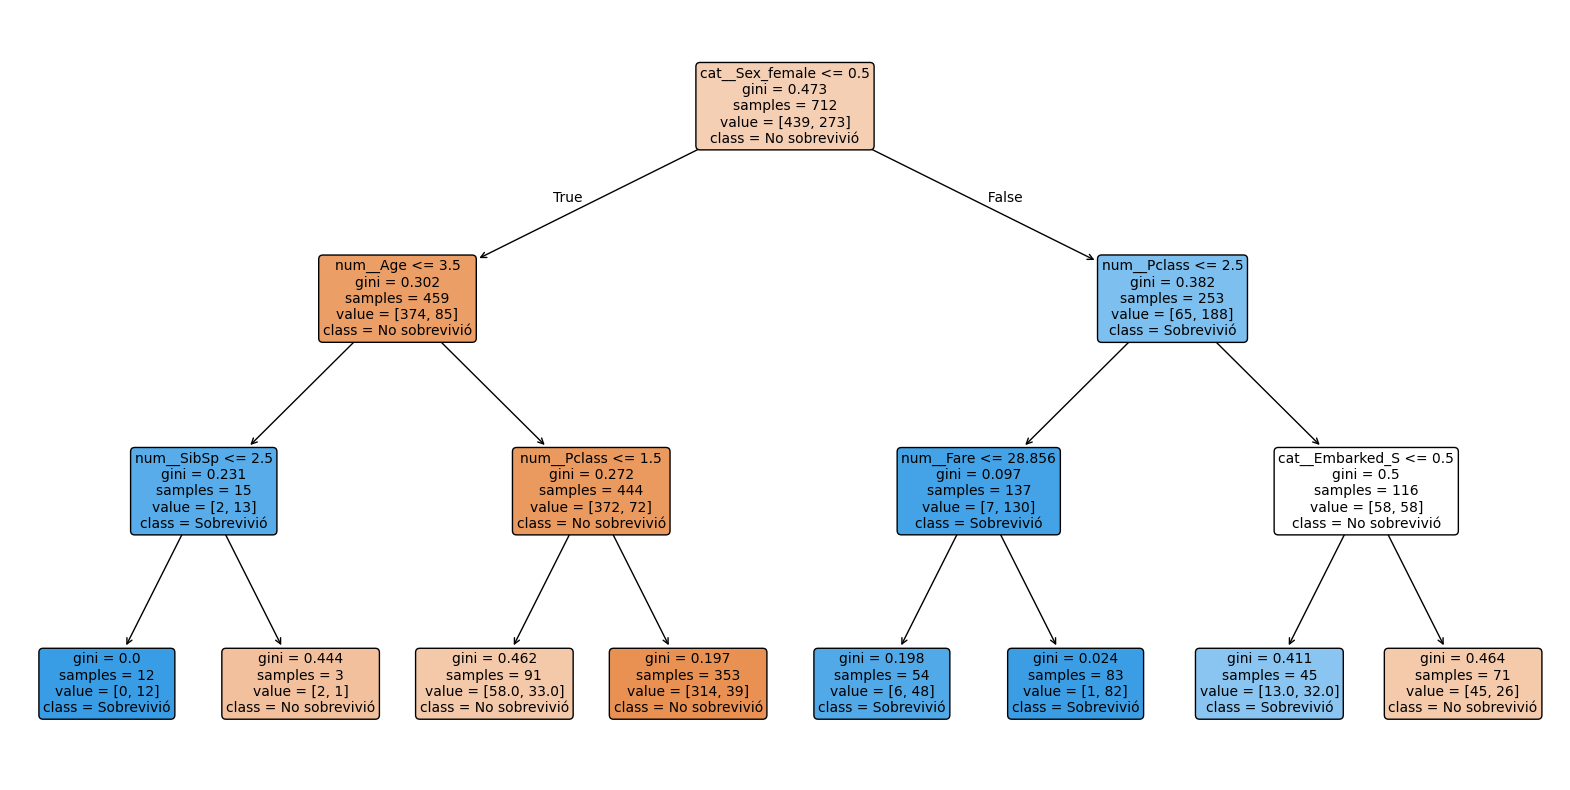

|--- cat__Sex_female <= 0.50
|   |--- num__Age <= 3.50
|   |   |--- num__SibSp <= 2.50
|   |   |   |--- class: 1
|   |   |--- num__SibSp >  2.50
|   |   |   |--- class: 0
|   |--- num__Age >  3.50
|   |   |--- num__Pclass <= 1.50
|   |   |   |--- class: 0
|   |   |--- num__Pclass >  1.50
|   |   |   |--- class: 0
|--- cat__Sex_female >  0.50
|   |--- num__Pclass <= 2.50
|   |   |--- num__Fare <= 28.86
|   |   |   |--- class: 1
|   |   |--- num__Fare >  28.86
|   |   |   |--- class: 1
|   |--- num__Pclass >  2.50
|   |   |--- cat__Embarked_S <= 0.50
|   |   |   |--- class: 1
|   |   |--- cat__Embarked_S >  0.50
|   |   |   |--- class: 0



In [21]:
arbol = pipe_tree.named_steps["tree"]
features = pipe_tree.named_steps["prep"].get_feature_names_out()

plt.figure(figsize=(20, 10))
plot_tree(
    arbol,
    feature_names=features,
    class_names=["No sobrevivió", "Sobrevivió"],
    filled=True,
    rounded=True,
    fontsize=10,
)
plt.show()

# Versión en texto (útil para árboles profundos)
print(export_text(arbol, feature_names=list(features)))

### Parte 3 - Transformador customizado

`TitanicFeatures` recupera información de las columnas que antes se descartaban:

- `Title`: título extraído de `Name` (Mr, Mrs, Miss, Master, Rare).
- `FamilySize` / `IsAlone`: a partir de `SibSp + Parch`.
- `HasCabin`: si tenía camarote asignado (el nulo en `Cabin` es información en sí).
- `log_fare`: opcional, reduce el sesgo de `Fare`.

Cada feature se activa con un parámetro, lo que permite comparar variantes de transformación × clasificador (KNN, Árbol, Naive Bayes) con validación cruzada.

In [22]:
from sklearn.base import BaseEstimator, TransformerMixin


class TitanicFeatures(BaseEstimator, TransformerMixin):
    """Crea features a partir de columnas que en las partes 1 y 2 descartábamos."""

    TITULOS = {
        "Mr": "Mr", "Mrs": "Mrs", "Miss": "Miss", "Master": "Master",
        "Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs",
    }

    def __init__(self, titulo=True, familia=True, cabina=True, log_fare=False):
        self.titulo = titulo
        self.familia = familia
        self.cabina = cabina
        self.log_fare = log_fare

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        if self.titulo:
            X["Title"] = (
                X["Name"].str.extract(r",\s*([^\.]+)\.")[0]
                .map(self.TITULOS)
                .fillna("Rare")
            )
        if self.familia:
            X["FamilySize"] = X["SibSp"] + X["Parch"] + 1
            X["IsAlone"] = (X["FamilySize"] == 1).astype(int)
        if self.cabina:
            X["HasCabin"] = X["Cabin"].notna().astype(int)
        if self.log_fare:
            X["Fare"] = np.log1p(X["Fare"])
        return X.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"])


TitanicFeatures().fit_transform(X_train).head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Title,FamilySize,IsAlone,HasCabin
692,3,male,NaN,0,0,56.4958,S,Mr,1,1,0
481,2,male,NaN,0,0,0.0000,S,Mr,1,1,0
527,1,male,NaN,0,0,221.7792,S,Mr,1,1,1
855,3,female,18.0,0,1,9.3500,S,Mrs,2,0,0
801,2,female,31.0,1,1,26.2500,S,Mrs,3,0,0


In [23]:
from sklearn.compose import make_column_selector
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import cross_val_score


def armar_pipeline(clf, escalar=True, **features):
    pasos_num = [("imputer", SimpleImputer(strategy="median"))]
    if escalar:
        pasos_num.append(("scaler", StandardScaler()))

    # Selección por tipo: las columnas nuevas entran solas en num o cat
    prep = ColumnTransformer([
        ("num", Pipeline(pasos_num), make_column_selector(dtype_include="number")),
        ("cat", pipe_cat, make_column_selector(dtype_include="object")),
    ], sparse_threshold=0)  # GaussianNB no acepta matrices sparse

    return Pipeline([
        ("features", TitanicFeatures(**features)),
        ("prep", prep),
        ("clf", clf),
    ])


clasificadores = {
    # nombre: (clasificador, escalar)
    "KNN": (KNeighborsClassifier(n_neighbors=5), True),
    "Árbol": (DecisionTreeClassifier(max_depth=3, random_state=42), False),
    "Naive Bayes": (GaussianNB(), True),
}

variantes = {
    "base (= Parte 1)": dict(titulo=False, familia=False, cabina=False),
    "+ título": dict(titulo=True, familia=False, cabina=False),
    "+ título + familia + cabina": dict(),
    "todo + log(Fare)": dict(log_fare=True),
}

resultados = []
for nombre_clf, (clf, escalar) in clasificadores.items():
    for nombre_var, params in variantes.items():
        pipe = armar_pipeline(clf, escalar, **params)
        scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring="accuracy")
        resultados.append({
            "clasificador": nombre_clf,
            "variante": nombre_var,
            "accuracy_cv": scores.mean(),
            "std": scores.std(),
        })

tabla = pd.DataFrame(resultados).sort_values("accuracy_cv", ascending=False)
tabla

,clasificador,variante,accuracy_cv,std
6,Árbol,+ título + familia + cabina,0.817542,0.040309
7,Árbol,todo + log(Fare),0.817542,0.040309
3,KNN,todo + log(Fare),0.817483,0.029308
2,KNN,+ título + familia + cabina,0.813306,0.040506
1,KNN,+ título,0.813237,0.019836
5,Árbol,+ título,0.811898,0.037498
0,KNN,base (= Parte 1),0.810470,0.024893
4,Árbol,base (= Parte 1),0.809071,0.031886
11,Naive Bayes,todo + log(Fare),0.803388,0.026158
10,Naive Bayes,+ título + familia + cabina,0.801999,0.030961


In [24]:
mejor = tabla.iloc[0]
clf, escalar = clasificadores[mejor["clasificador"]]
pipe_final = armar_pipeline(clf, escalar, **variantes[mejor["variante"]])

pipe_final.fit(X_train, y_train)
y_pred = pipe_final.predict(X_test)

print(f"Mejor: {mejor['clasificador']} | {mejor['variante']}")
print("Accuracy test:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Mejor: Árbol | + título + familia + cabina
Accuracy test: 0.8324022346368715
              precision    recall  f1-score   support

           0       0.84      0.90      0.87       110
           1       0.82      0.72      0.77        69

    accuracy                           0.83       179
   macro avg       0.83      0.81      0.82       179
weighted avg       0.83      0.83      0.83       179



In [ ]:
mejor = tabla.iloc[1]
clf, escalar = clasificadores[mejor["clasificador"]]
pipe_final = armar_pipeline(clf, escalar, **variantes[mejor["variante"]])

pipe_final.fit(X_train, y_train)
y_pred = pipe_final.predict(X_test)

print(f" {mejor['clasificador']} | {mejor['variante']}")
print("Accuracy test:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Mejor: Árbol | todo + log(Fare)
Accuracy test: 0.8324022346368715
              precision    recall  f1-score   support

           0       0.84      0.90      0.87       110
           1       0.82      0.72      0.77        69

    accuracy                           0.83       179
   macro avg       0.83      0.81      0.82       179
weighted avg       0.83      0.83      0.83       179



In [26]:
mejor = tabla.iloc[2]
clf, escalar = clasificadores[mejor["clasificador"]]
pipe_final = armar_pipeline(clf, escalar, **variantes[mejor["variante"]])

pipe_final.fit(X_train, y_train)
y_pred = pipe_final.predict(X_test)

print(f" {mejor['clasificador']} | {mejor['variante']}")
print("Accuracy test:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

 KNN | todo + log(Fare)
Accuracy test: 0.7932960893854749
              precision    recall  f1-score   support

           0       0.82      0.85      0.83       110
           1       0.74      0.71      0.73        69

    accuracy                           0.79       179
   macro avg       0.78      0.78      0.78       179
weighted avg       0.79      0.79      0.79       179



## Conclusiones

**Preprocesamiento**
- Se descartaron `PassengerId`, `Name`, `Ticket` y `Cabin` en su forma cruda: son identificadores, texto libre o tienen demasiados nulos (77% en `Cabin`).
- Imputación por mediana en numéricas (cubre el ~20% de nulos de `Age`) y por moda + One-Hot en categóricas.
- El escalado es necesario para KNN y Naive Bayes, pero no para el árbol: los cortes por umbral no dependen de la escala, y sin escalar el árbol queda interpretable en unidades reales (años, tarifa).

**Transformador customizado (`TitanicFeatures`)**
- Recuperar información de las columnas descartadas mejoró a los tres clasificadores respecto de la Parte 1:

| Clasificador | Base (Parte 1) | Mejor variante | Accuracy CV |
|---|---|---|---|
| Árbol (`max_depth=3`) | 0.809 | título + familia + cabina | **0.818** |
| KNN (`k=5`) | 0.810 | todo + log(Fare) | 0.816 |
| Naive Bayes | 0.789 | todo + log(Fare) | 0.803 |

- Agregar solo `Title` ya mejora a los tres modelos (resume sexo, edad y estatus social); Naive Bayes es el que más se beneficia (0.789 → 0.799).
- `log(Fare)` ayuda a KNN y Naive Bayes, pero no cambia nada en el árbol: el logaritmo preserva el orden y el árbol elige los mismos cortes (por eso los dos primeros puestos son idénticos).

**Evaluación**
- Los modelos se compararon con validación cruzada (5 folds) sobre el train, reservando el test solo para la evaluación final.
- La mejor opción fue el **árbol de decisión con título + familia + cabina**: 0.818 en CV y **0.832 en test**.
- Las diferencias entre los primeros puestos son menores al desvío de la CV (±0.03–0.04), por lo que no hay un ganador estadísticamente claro. KNN lo ilustra: empata en CV (0.816) pero obtiene 0.793 en test.
- En los modelos evaluados en test, el recall de "sobrevivió" (0.71–0.72) es bastante menor que el de "no sobrevivió" (0.85–0.90): se detecta peor a los sobrevivientes, en parte por el desbalance de clases (62% / 38%).

**Posibles mejoras**
- Ajustar hiperparámetros con `GridSearchCV` (`max_depth`, `min_samples_leaf`, `n_neighbors`) en lugar de probar manualmente.
- Imputar `Age` con la mediana por `Title` en vez de la mediana global.
- Probar ensambles (Random Forest, Gradient Boosting) y `class_weight="balanced"` para mejorar el recall de sobrevivientes.